# How much does a nuclear boundary matter?

A brown pixel next to a nucleus can enter the nuclear average, the perinuclear average, or neither. This walkthrough follows one synthetic field from its RGB pixels to a per-cell measurement, then moves the segmentation boundary by two pixels and measures the consequences. Each figure and table below is computed by the included Python package.

Install this checkout with `python -m pip install -e '.[notebook]'` in the repository root. All inputs in this walkthrough are generated in memory. Change the seed to draw another field.

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
from ihc_demo.phantom import build_phantom
from ihc_demo.measurement import quantify
from ihc_demo.analysis import recovery, ring_sweep
from ihc_demo.stress import mask_stress
from ihc_demo.figures import overview_figure, qc_figure

rgb, labels, truth = build_phantom(seed=17)
cells, rings, dab_od = quantify(rgb, labels, outer_scale=1.5)
print(f'{rgb.shape[1]} × {rgb.shape[0]} pixels, {len(cells)} labeled synthetic nuclei')

560 × 470 pixels, 58 labeled synthetic nuclei


## Inspect the measurement regions

The input mask assigns one ID per nucleus. An external band is grown by half the equivalent nuclear radius, with competing pixels assigned to a single nearest nucleus. A separate channel estimates DAB stain strength. Look for an ochre nuclear contour with brown stain concentrated in the teal region around it.

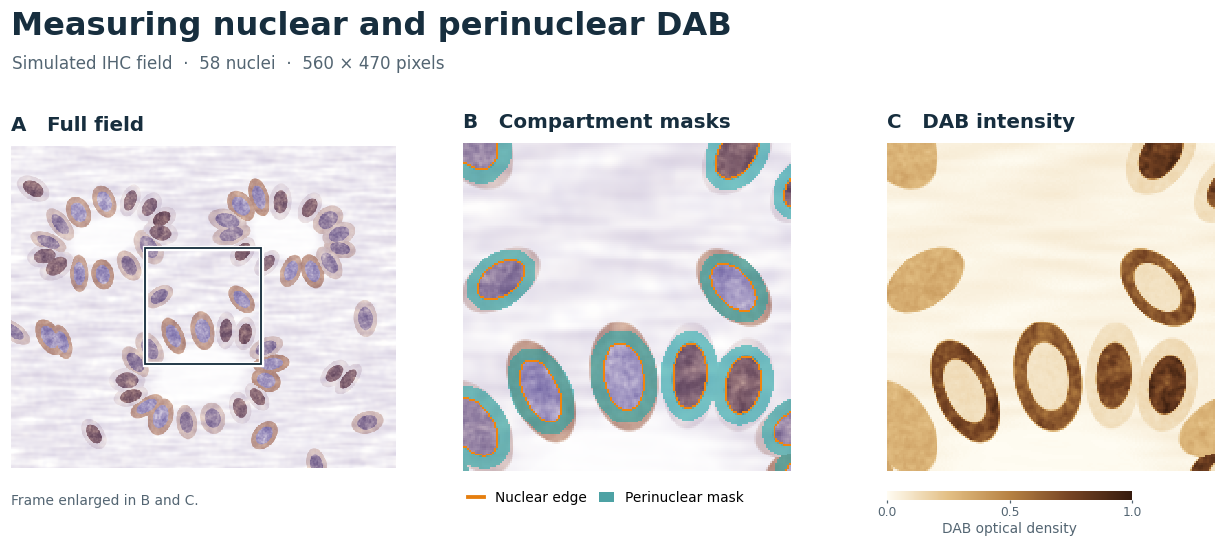

In [2]:
fig = overview_figure(rgb, labels, rings, dab_od, cells)
display(fig)
plt.close(fig)

## Inspect three cells and the support behind each ratio

Each example below is the first generated cell of its phenotype. The ratio divides the mean ring signal by the mean nuclear signal. A ring with substantial overlap pressure can be useful for inspection even when its geometry is imperfect. Both the observed area and the quality flags travel with each result.

In [3]:
joined = cells.merge(truth, on='cell_id', validate='one_to_one')
columns = ['cell_id', 'phenotype', 'ring_area_px', 'ring_area_fraction',
           'nuclear_mean_dab_od', 'ring_mean_dab_od', 'ring_to_nucleus_ratio', 'qc_flags']
representatives = joined.groupby('phenotype', sort=True).head(1)
display(representatives[columns].round(3))
display(cells['qc_flags'].value_counts().rename('cells').to_frame())

,cell_id,phenotype,ring_area_px,ring_area_fraction,nuclear_mean_dab_od,ring_mean_dab_od,ring_to_nucleus_ratio,qc_flags
0,1,nuclear-enriched,324,0.632,0.855,0.154,0.180,crowded
2,3,balanced,632,0.810,0.295,0.304,1.030,crowded
4,5,ring-enriched,518,0.942,0.139,0.722,5.204,ok


,cells
qc_flags,
crowded,35
ok,21
edge,2


## Test target recovery and change the sampling radius

The renderer places the perinuclear signal in an elliptical band. The estimator follows a discrete distance from the segmented nuclear outline. These choices disagree most around elongated nuclei and their neighbors. The scatter plot compares estimated means with the assigned targets. The second panel keeps every nucleus fixed and changes the radius of the measured band.

,compartment,cells_total,cells_measured,rank_correlation,mean_absolute_error_od,mean_signed_error_od
0,nuclear,58,58,0.9972,0.0118,-0.0012
1,ring,58,58,0.9923,0.0107,-0.0023


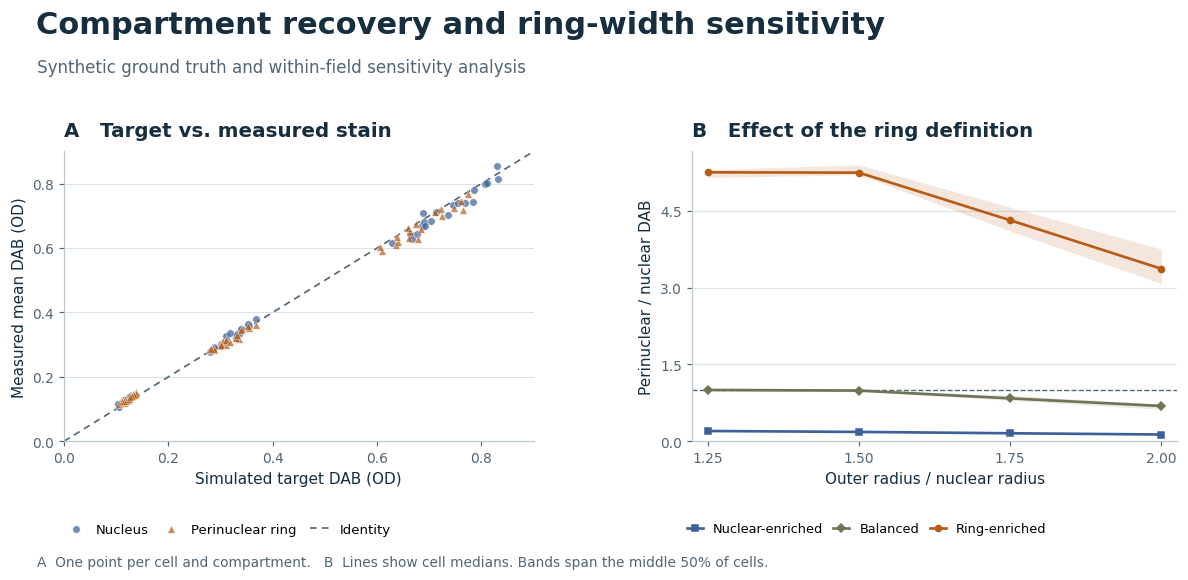

In [4]:
display(recovery(cells, truth).round(4))
sensitivity = ring_sweep(rgb, labels, truth, baseline=cells)
fig = qc_figure(cells, truth, sensitivity)
display(fig)
plt.close(fig)

## Introduce a known segmentation error

The reference and perturbed measurements below use identical color pixels, cell identities and target values. The only change is a two-pixel displacement of the supplied nuclear boundary. Check the number of cells measured alongside the error. Could an attractive rank correlation hide an absolute measurement bias?

In [5]:
stress = mask_stress(rgb, labels, truth)
ring = stress.loc[stress['compartment'].eq('ring')].set_index('mask_condition')
display(ring[['cells_total', 'cells_measured', 'mean_absolute_error_od',
              'mean_signed_error_od', 'rank_correlation']].round(4))

,cells_total,cells_measured,mean_absolute_error_od,mean_signed_error_od,rank_correlation
mask_condition,,,,,
reference,58,58,0.0107,-0.0023,0.9923
eroded_2px,58,58,0.1398,0.0139,0.6982
dilated_2px,58,58,0.0630,-0.0630,0.9739


## Interpretation

In the default field, erosion contaminates the ring with signal from the original nucleus. Dilation pushes the ring toward surrounding tissue. After dilation, the cells still rank similarly to their targets while the magnitude of the error has grown. This is why the repository reports absolute error as well as rank agreement.

The synthetic generator and estimator share stain vectors, and the phantom supplies the reference nuclei. Real slides would introduce segmentation errors, tissue selection, calibration drift and biological variability. The ring is an external sampling band around a nucleus and cannot establish a true cell boundary. The [methods](../METHODS.md) document the assumptions and all flags. The [five-seed benchmark](../examples/mask_stress.csv) records the same experiment across additional realizations.